# 1. Data loading

Download necessary libraries to process the dataset

In [1]:
#!pip install pandas numpy matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path #To manage the routes of the data
import gzip #As the data comes in .gz packages
import struct
import sys

**Load the Dataset**

In [ ]:

# Locate the project root whether Jupyter starts in the root or notebooks/
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "src" / "data_loader.py").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "src" / "data_loader.py").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate src/data_loader.py. Check your working directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw_dataset, CLASS_NAMES

# Load the original training and test sets
X_train_3d, y_train_raw, X_test_3d, y_test_raw = load_raw_dataset()

# Flatten images into 784 features for statistical analysis and classical ML
X_train_2d = X_train_3d.reshape(X_train_3d.shape[0], -1)
X_test_2d = X_test_3d.reshape(X_test_3d.shape[0], -1)

# Reuse the class names defined in data_loader.py
class_names = CLASS_NAMES
labels_dict = dict(enumerate(CLASS_NAMES))

# Verify the loaded data
print("=" * 50)
print("FASHION-MNIST DATA LOADED")
print("=" * 50)
print(f"Training images (3D): {X_train_3d.shape}")
print(f"Training images (2D): {X_train_2d.shape}")
print(f"Training labels:      {y_train_raw.shape}")
print(f"Test images (3D):     {X_test_3d.shape}")
print(f"Test images (2D):     {X_test_2d.shape}")
print(f"Test labels:          {y_test_raw.shape}")
print(f"Image data type:      {X_train_3d.dtype}")
print(f"Label data type:      {y_train_raw.dtype}")


FASHION-MNIST DATA LOADED
Training images (3D): (60000, 28, 28)
Training images (2D): (60000, 784)
Training labels:      (60000,)
Test images (3D):     (10000, 28, 28)
Test images (2D):     (10000, 784)
Test labels:          (10000,)
Image data type:      uint8
Label data type:      uint8


# Exploratory Data Analysis (EDA)

Fashion-MNIST contains 70,000 grayscale images across 10 categories: 60,000 for training and 10,000 for testing.

This section covers five aspects:

- **Target Distribution:** Sample counts and class proportions.
- **Data Quality:** Dimensions, data types, missing values, and pixel ranges.
- **Visual Inspection:** Random samples and average images to examine intra-class variation.
- **Pixel Intensity Statistics:** Distribution of pixel values and proportion of black background pixels.
- **Spatial Variability and PCA:** Pixel-level variation and 2D class separation.

In [3]:
# Official label-category mapping of Fashion-MNIST
labels_dict = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

class_names = [labels_dict[i] for i in range(10)]

print("Category mapping configuration succesful:")
for i in range(10):
    print(f"  Category {i}: {labels_dict[i]:<15}")


Category mapping configuration succesful:
  Category 0: T-shirt/top    
  Category 1: Trouser        
  Category 2: Pullover       
  Category 3: Dress          
  Category 4: Coat           
  Category 5: Sandal         
  Category 6: Shirt          
  Category 7: Sneaker        
  Category 8: Bag            
  Category 9: Ankle boot     


### 1 Data Quality and Integrity

The extracted data is checked for completeness and consistency:

- No missing or `NaN` values in the images or labels.
- Each image contains 784 pixels (28 × 28).
- Pixel values range from 0 to 255 (`uint8`).
- Labels are integers from 0 to 9.

In [ ]:
# 1 Data Quality and Integrity
total_train = len(y_train_raw)
total_test = len(y_test_raw)

nulls_train_X = int(np.isnan(X_train_2d).sum())
nulls_test_X = int(np.isnan(X_test_2d).sum())
nulls_train_y = int(np.isnan(y_train_raw).sum())
nulls_test_y = int(np.isnan(y_test_raw).sum())

range_train_X = (int(X_train_2d.min()), int(X_train_2d.max()))
range_test_X = (int(X_test_2d.min()), int(X_test_2d.max()))
range_train_y = (int(y_train_raw.min()), int(y_train_raw.max()))
range_test_y = (int(y_test_raw.min()), int(y_test_raw.max()))

quality_df = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Total Samples": [total_train, total_test],
    "Dimensions": [str(X_train_2d.shape), str(X_test_2d.shape)],
    "Data Type": [str(X_train_2d.dtype), str(X_test_2d.dtype)],
    "Missing Values in X": [nulls_train_X, nulls_test_X],
    "Missing Values in y": [nulls_train_y, nulls_test_y],
    "Pixel Range": [
        f"[{range_train_X[0]}, {range_train_X[1]}]",
        f"[{range_test_X[0]}, {range_test_X[1]}]"
    ],
    "Label Range": [
        f"[{range_train_y[0]}, {range_train_y[1]}]",
        f"[{range_test_y[0]}, {range_test_y[1]}]"
    ],
    "Usable Data (%)": ["100.0%", "100.0%"]
})

print("=" * 80)
print("Data Quality and Integrity Report")
print("=" * 80)
display(quality_df)

Data Quality and Integrity Report


,Set,Total Samples,Dimensions,Data Type,Missing Values in X,Missing Values in y,Pixel Range,Label Range,Usable Data (%)
0,Train,60000,"(60000, 784)",uint8,0,0,"[0, 255]","[0, 9]",100.0%
1,Test,10000,"(10000, 784)",uint8,0,0,"[0, 255]","[0, 9]",100.0%


### Target Variable Distribution and Class Balance

Class balance helps prevent models from favoring certain categories. It is evaluated using the *Imbalance Ratio*:

$$\text{Imbalance Ratio} = \frac{\text{Majority Class Samples}}{\text{Minority Class Samples}}$$

- A value of **1.0** indicates perfect balance.
- Values above **1.5** may indicate substantial imbalance requiring techniques such as oversampling or class weighting.

Imbalance Ratio (Train): 1.00
Imbalance Ratio (Test):  1.00
Result: The dataset is balanced, with 10% per class in both sets.
--------------------------------------------------------------------------------


,Label,Class,Train (Count),Train (%),Test (Count),Test (%)
0,0,T-shirt/top,6000,10.0,1000,10.0
1,1,Trouser,6000,10.0,1000,10.0
2,2,Pullover,6000,10.0,1000,10.0
3,3,Dress,6000,10.0,1000,10.0
4,4,Coat,6000,10.0,1000,10.0
5,5,Sandal,6000,10.0,1000,10.0
6,6,Shirt,6000,10.0,1000,10.0
7,7,Sneaker,6000,10.0,1000,10.0
8,8,Bag,6000,10.0,1000,10.0
9,9,Ankle boot,6000,10.0,1000,10.0


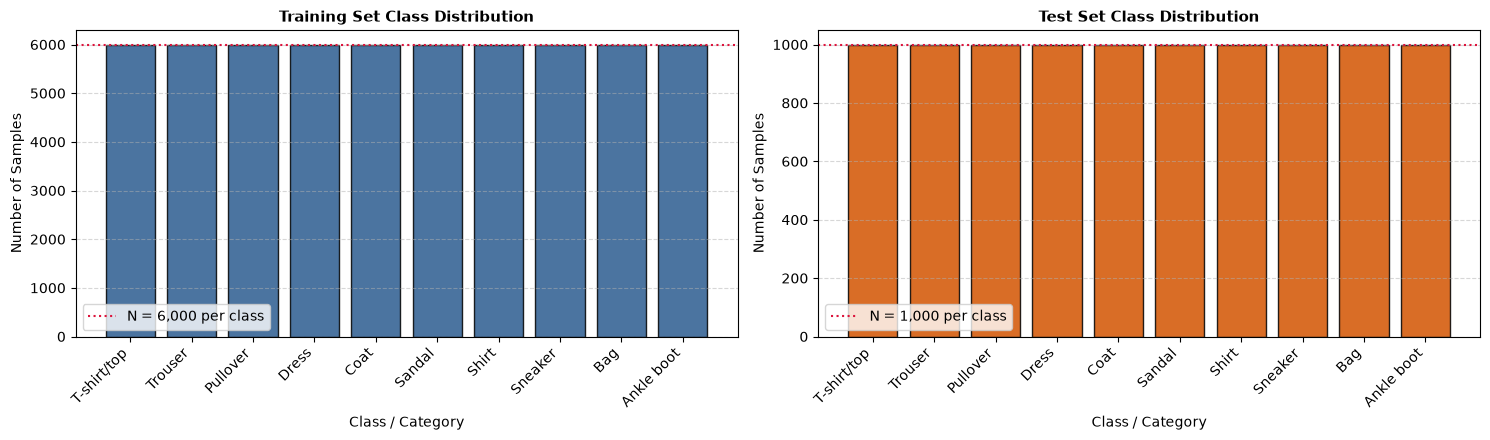

In [18]:
# 2.2 Class Distribution and Imbalance Ratio
train_counts = pd.Series(y_train_raw).value_counts().sort_index()
test_counts = pd.Series(y_test_raw).value_counts().sort_index()

df_distribution = pd.DataFrame({
    "Label": range(10),
    "Class": class_names,
    "Train (Count)": train_counts.values,
    "Train (%)": (train_counts.values / total_train) * 100,
    "Test (Count)": test_counts.values,
    "Test (%)": (test_counts.values / total_test) * 100
})

ir_train = train_counts.max() / train_counts.min()
ir_test = test_counts.max() / test_counts.min()

print(f"Imbalance Ratio (Train): {ir_train:.2f}")
print(f"Imbalance Ratio (Test):  {ir_test:.2f}")
print("Result: The dataset is balanced, with 10% per class in both sets.")
print("-" * 80)
display(df_distribution)

# Visualize class distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)

axes[0].bar(
    range(10), train_counts.values,
    color="#2b5c8f", edgecolor="black", alpha=0.85
)
axes[0].set_title(
    "Training Set Class Distribution",
    fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Class / Category", fontsize=10)
axes[0].set_ylabel("Number of Samples", fontsize=10)
axes[0].set_xticks(range(10))
axes[0].set_xticklabels(class_names, rotation=45, ha="right")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].axhline(
    y=6000, color="crimson", linestyle=":",
    label="N = 6,000 per class"
)
axes[0].legend()

axes[1].bar(
    range(10), test_counts.values,
    color="#d35400", edgecolor="black", alpha=0.85
)
axes[1].set_title(
    "Test Set Class Distribution",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Class / Category", fontsize=10)
axes[1].set_ylabel("Number of Samples", fontsize=10)
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(class_names, rotation=45, ha="right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].axhline(
    y=1000, color="crimson", linestyle=":",
    label="N = 1,000 per class"
)
axes[1].legend()

plt.tight_layout()
plt.show()

### 3 Visual Inspection: Intra-Class Variability and Mean Images

#### Random Sample Gallery

Random samples illustrate variations within each class. For example, dresses and coats differ in length, shape, and thickness, while bag strap orientation creates additional variations.

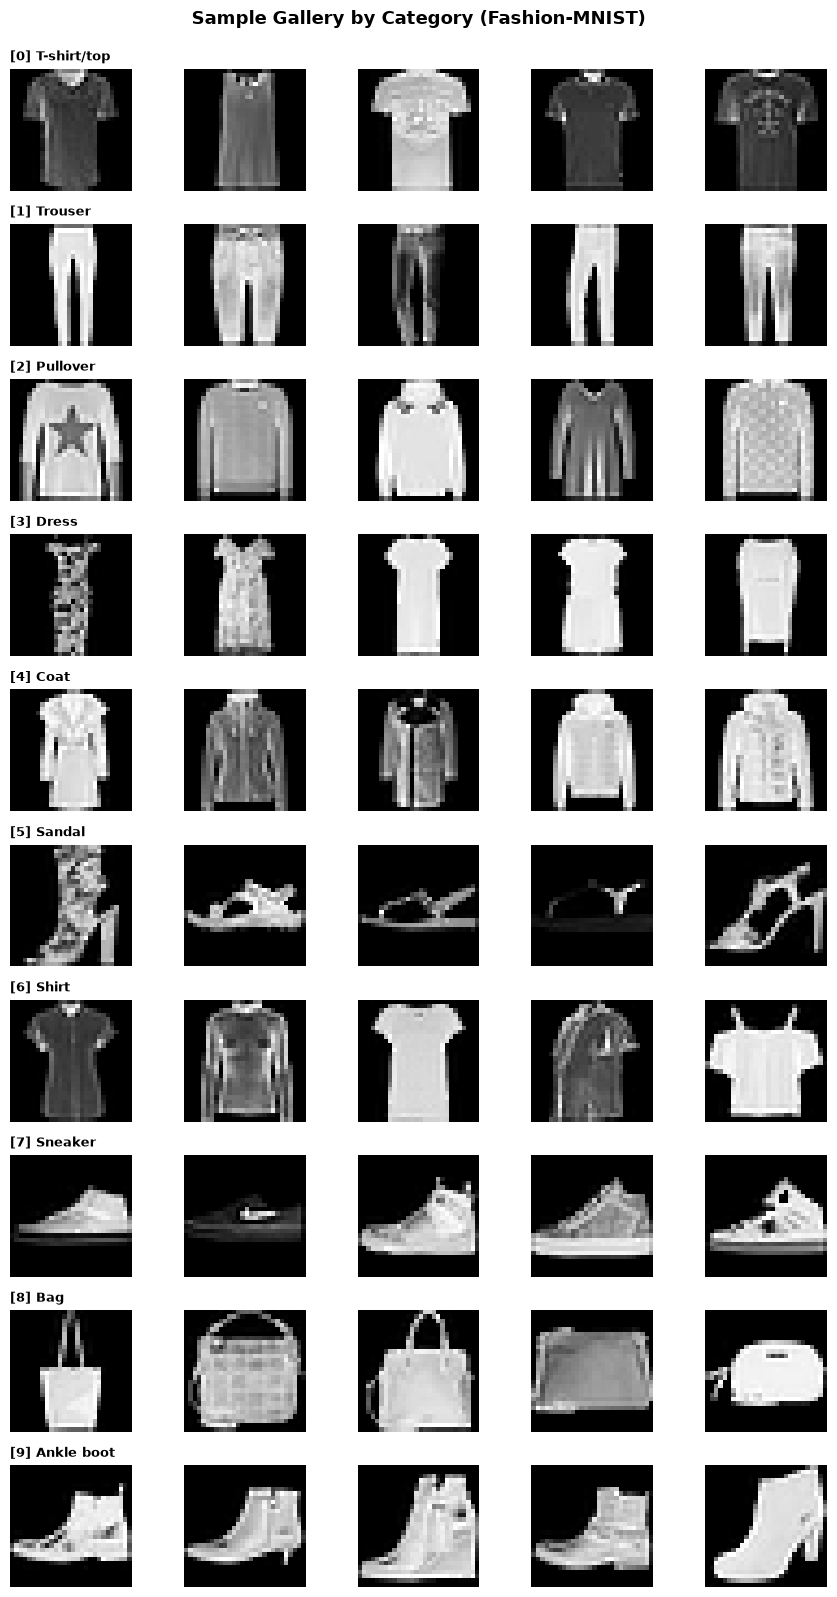

In [ ]:
# 3.1 Display 5 samples per class to examine intra-class variability
np.random.seed(42)
n_samples = 5

fig, axes = plt.subplots(10, n_samples, figsize=(9, 16))
fig.suptitle(
    "Sample Gallery by Category (Fashion-MNIST)",
    fontsize=13, fontweight="bold", y=0.995
)

for label_idx in range(10):
    class_indices = np.where(y_train_raw == label_idx)[0]
    chosen_indices = np.random.choice(
        class_indices, n_samples, replace=False
    )

    for col_idx, img_idx in enumerate(chosen_indices):
        ax = axes[label_idx, col_idx]
        ax.imshow(X_train_3d[img_idx], cmap="gray")
        ax.axis("off")

        if col_idx == 0:
            ax.set_title(
                f"[{label_idx}] {labels_dict[label_idx]}",
                fontsize=9, loc="left", fontweight="bold"
            )

plt.tight_layout()
plt.show()

#### Mean Image per Category

Averaging each pixel across all images in a class produces a representative spatial pattern:

- Brighter regions indicate areas commonly occupied by the item.
- Fainter regions indicate greater variation in shape, size, or position.

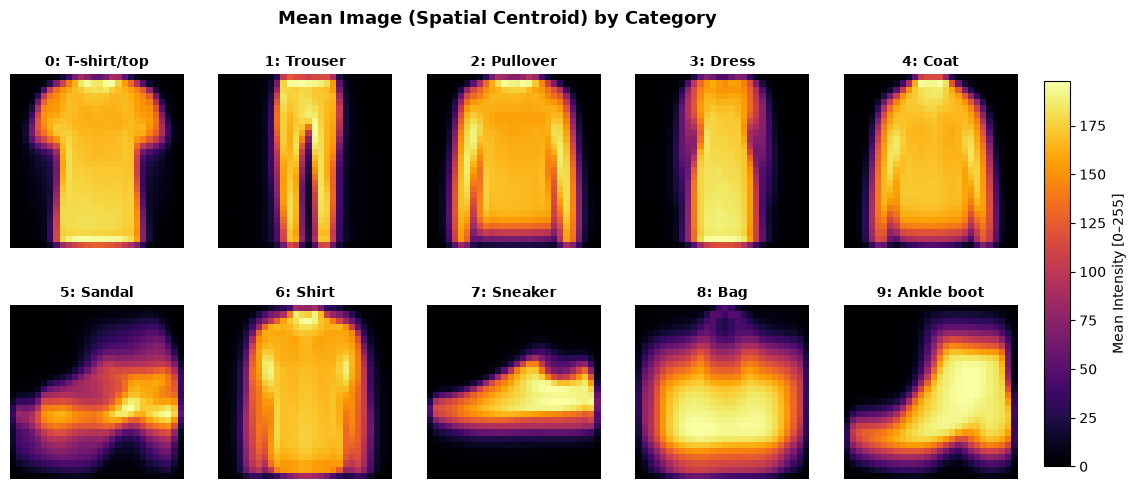

In [ ]:
# 3.2 Calculate and display the mean image for each class
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
fig.suptitle(
    "Mean Image (Spatial Centroid) by Category",
    fontsize=13, fontweight="bold"
)

for label_idx in range(10):
    ax = axes[label_idx // 5, label_idx % 5]
    class_images = X_train_3d[y_train_raw == label_idx]
    mean_img = np.mean(class_images, axis=0)

    im = ax.imshow(mean_img, cmap="inferno")
    ax.set_title(
        f"{label_idx}: {labels_dict[label_idx]}",
        fontsize=10, fontweight="bold"
    )
    ax.axis("off")

# Mean pixel intensity color scale
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Mean Intensity [0–255]")
plt.subplots_adjust(right=0.9)
plt.show()

### 4 Descriptive Statistics of Pixel Intensities

Each image contains 784 grayscale pixels, with values ranging from 0 (black) to 255 (white).

The training set is analyzed to examine the distribution of pixel intensities, including the proportion of black background pixels. A logarithmic histogram helps visualize both frequent and less common intensity values.

PIXEL INTENSITY STATISTICAL SUMMARY


,Metric,Value
0,Total Pixels Evaluated,"47,040,000"
1,Minimum Value,0
2,First Quartile (Q1 - 25%),0.0
3,Median (Q2 - 50%),0.0
4,Global Mean,72.94
5,Standard Deviation (std),90.02
6,Third Quartile (Q3 - 75%),163.0
7,Maximum Value,255
8,Pure Background Pixels (Value = 0),50.21%


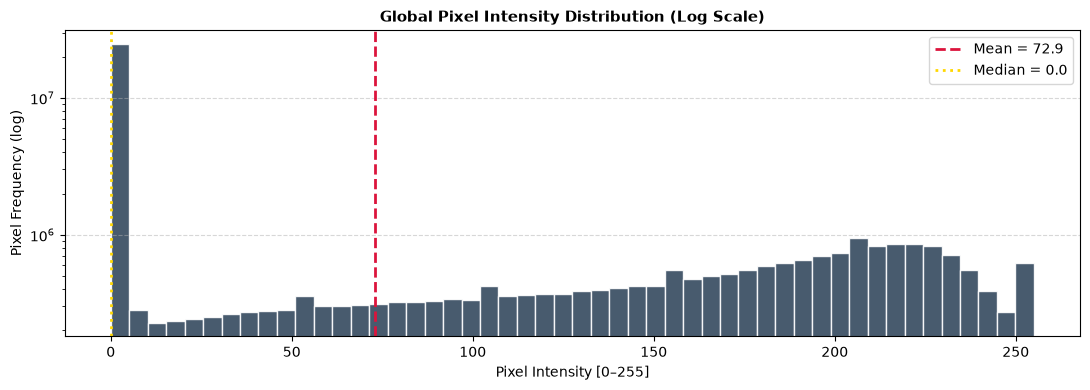

In [ ]:
# 4 Global pixel statistics and intensity histogram
pixel_vals = X_train_2d.flatten()

stats_summary = pd.DataFrame({
    "Metric": [
        "Total Pixels Evaluated",
        "Minimum Value",
        "First Quartile (Q1 - 25%)",
        "Median (Q2 - 50%)",
        "Global Mean",
        "Standard Deviation (std)",
        "Third Quartile (Q3 - 75%)",
        "Maximum Value",
        "Pure Background Pixels (Value = 0)"
    ],
    "Value": [
        f"{len(pixel_vals):,}",
        f"{pixel_vals.min()}",
        f"{np.percentile(pixel_vals, 25):.1f}",
        f"{np.median(pixel_vals):.1f}",
        f"{pixel_vals.mean():.2f}",
        f"{pixel_vals.std():.2f}",
        f"{np.percentile(pixel_vals, 75):.1f}",
        f"{pixel_vals.max()}",
        f"{(pixel_vals == 0).sum() / len(pixel_vals) * 100:.2f}%"
    ]
})

print("=" * 60)
print("PIXEL INTENSITY STATISTICAL SUMMARY")
print("=" * 60)
display(stats_summary)

# Pixel intensity histogram
plt.figure(figsize=(11, 4))
plt.hist(
    pixel_vals, bins=50,
    color="#34495e", edgecolor="white",
    alpha=0.9, log=True
)
plt.title(
    "Global Pixel Intensity Distribution (Log Scale)",
    fontsize=11, fontweight="bold"
)
plt.xlabel("Pixel Intensity [0–255]", fontsize=10)
plt.ylabel("Pixel Frequency (log)", fontsize=10)

plt.axvline(
    pixel_vals.mean(), color="crimson",
    linestyle="--", linewidth=2,
    label=f"Mean = {pixel_vals.mean():.1f}"
)
plt.axvline(
    np.median(pixel_vals), color="gold",
    linestyle=":", linewidth=2,
    label=f"Median = {np.median(pixel_vals):.1f}"
)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 5 Spatial Variability and Class Separation with PCA

#### 5.1 Spatial Standard Deviation Map

Pixel-wise standard deviation reveals which image regions vary most across the training set. Low-variation regions typically correspond to the black background, while the central region contains more variation from the clothing items.

#### 5.2 2D PCA Projection

PCA reduces the 784 original features to two principal components. A sample of 5,000 images is projected into two dimensions to visualize class overlap and separation before training the models.

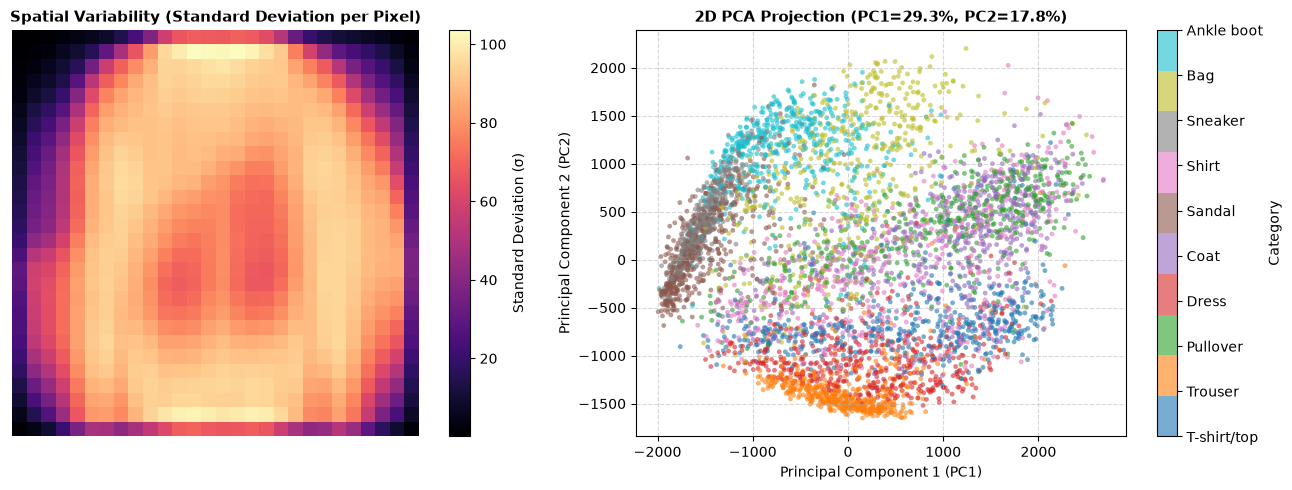

In [22]:
from sklearn.decomposition import PCA

# 1. Spatial variability map (standard deviation per pixel)
pixel_std_spatial = np.std(X_train_3d, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im_std = axes[0].imshow(pixel_std_spatial, cmap="magma")
axes[0].set_title(
    "Spatial Variability (Standard Deviation per Pixel)",
    fontsize=11, fontweight="bold"
)
axes[0].axis("off")
fig.colorbar(im_std, ax=axes[0], label="Standard Deviation (σ)")

# 2. 2D PCA using a representative sample of 5,000 images
np.random.seed(42)
sample_idx = np.random.choice(
    len(X_train_2d), size=5000, replace=False
)
X_pca_sample = X_train_2d[sample_idx]
y_pca_sample = y_train_raw[sample_idx]

pca_model = PCA(n_components=2, random_state=42)
X_pca_2d = pca_model.fit_transform(X_pca_sample)
var_exp = pca_model.explained_variance_ratio_ * 100

cmap = plt.get_cmap("tab10", 10)
scatter = axes[1].scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y_pca_sample,
    cmap=cmap,
    alpha=0.6,
    s=12,
    edgecolors="none"
)

axes[1].set_title(
    f"2D PCA Projection (PC1={var_exp[0]:.1f}%, "
    f"PC2={var_exp[1]:.1f}%)",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Principal Component 1 (PC1)", fontsize=10)
axes[1].set_ylabel("Principal Component 2 (PC2)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

cbar = fig.colorbar(scatter, ax=axes[1], ticks=range(10))
cbar.set_ticklabels(class_names)
cbar.set_label("Category")

plt.tight_layout()
plt.show()

### EDA Findings and Conclusions

- **Data integrity:** All 70,000 images are expected to contain valid pixel values, with no missing values or inconsistent dimensions. No cleaning is needed if these checks pass.
- **Class balance:** Each class has 6,000 training samples and 1,000 test samples, giving an imbalance ratio of 1.0. Accuracy and macro-\(F_1\) are suitable evaluation metrics.
- **Background pixels:** The large proportion of zero-valued pixels makes feature scaling worth evaluating for models sensitive to feature magnitudes.
- **Spatial variability:** Image borders show little variation and may contribute less information to classification.
- **Class separation:** Footwear and bags tend to be more distinguishable in the PCA projection, while upper-body clothing categories overlap more and may be harder to classify.